In [11]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [12]:
tf.__version__

'2.16.2'

In [13]:
keras.__version__

'3.6.0'

In [33]:
fashion_mnist=keras.datasets.fashion_mnist
(X_train_full,y_train_full),(X_test,y_test)=fashion_mnist.load_data()

In [15]:
X_train_full.shape

(60000, 28, 28)

In [16]:
X_train_full.dtype

dtype('uint8')

In [17]:
class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal"
             ,"Shirt","Sneaker","Bag","Ankle boot"]

In [22]:
print(class_names[y_train_full[0]])

Ankle boot


In [34]:
X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.0

# Reshape data for Conv2D input
X_train = X_train.reshape(-1, 28, 28, 1)
X_valid = X_valid.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Convert labels to categorical (one-hot encoding)
y_train = to_categorical(y_train, 10)
y_valid = to_categorical(y_valid, 10)
y_test = to_categorical(y_test)

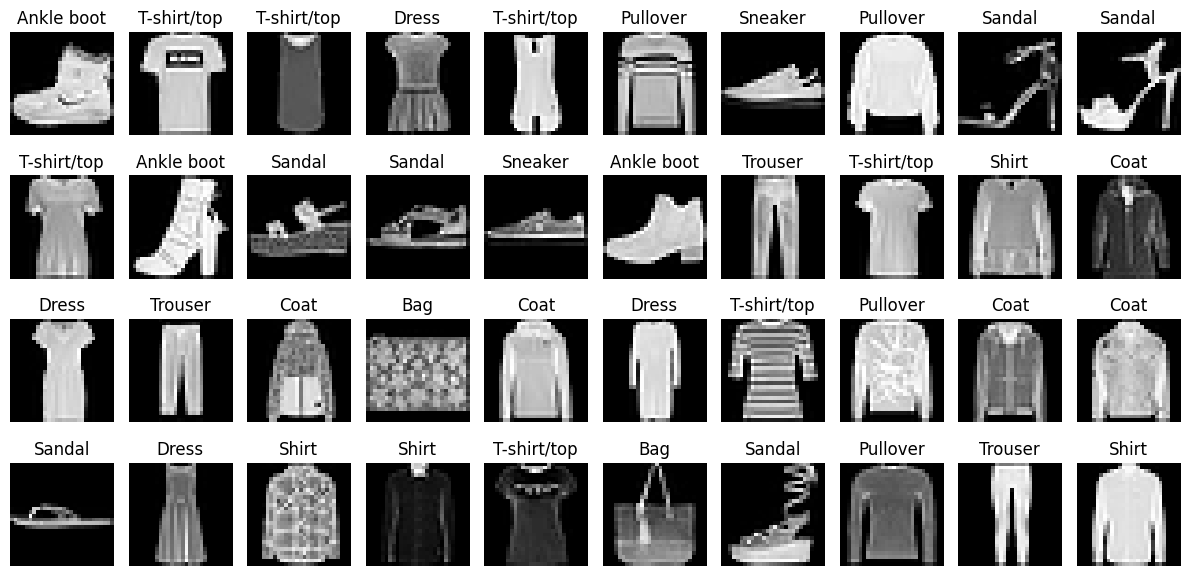

In [25]:
plt.figure(figsize=(12, 6))
for i in range(40):
    plt.subplot(4, 10, i + 1)
    plt.imshow(X_train_full[i], cmap='gray')  # Plot grayscale images
    plt.title(class_names[y_train_full[i]])  # Displaying class names
    plt.axis('off')  

plt.tight_layout()
plt.show()

In [26]:

# Define the checkpoint callback
checkpoint_callback = ModelCheckpoint(
    filepath='model_checkpoint.keras',     #Model file
    save_best_only=True,                # Saving the model with the best validation accuracy
    monitor='val_accuracy',             # Monitoring validation accuracy
    mode='max',                         # Mode for maximizing accuracy
    verbose=1                           # Printing verbose
)



In [27]:



# Sequential model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


# Training the model with the checkpoint callback
history = model.fit(
    X_train, y_train,batch_size=64,
    epochs=15,
    validation_data=(X_valid, y_valid),
    callbacks=[checkpoint_callback]     # Add checkpoint callback to the training
)

/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2024-10-31 20:01:07.746897: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2024-10-31 20:01:07.746952: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2024-10-31 20:01:07.746968: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2024-10-31 20:01:07.747210: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2024-10-31 20:01:07.747238: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory

Epoch 1/15


2024-10-31 20:01:08.608726: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6672 - loss: 0.9076
Epoch 1: val_accuracy improved from -inf to 0.85680, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.6674 - loss: 0.9073 - val_accuracy: 0.8568 - val_loss: 0.3960
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8328 - loss: 0.4618
Epoch 2: val_accuracy improved from 0.85680 to 0.87760, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.8328 - loss: 0.4617 - val_accuracy: 0.8776 - val_loss: 0.3334
Epoch 3/15
859/860 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8528 - loss: 0.3997
Epoch 3: val_accuracy improved from 0.87760 to 0.89440, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.8528 - loss: 0.3996 - val_accuracy: 0.8944 - val_loss: 0.2963
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8714 - loss: 0.3588
Epoch 4: val_accuracy im

In [32]:
y_test.shape

(10000, 10, 10, 2)

In [35]:
from tensorflow.keras.models import load_model

# Load the model from the saved checkpoint
saved_model = load_model('model_checkpoint.keras')

# Evaluate or use the model for predictions
test_loss, test_accuracy =saved_model.evaluate(X_test, y_test)
print(f'\nTest accuracy: {test_accuracy:.4f}')


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9081 - loss: 0.2528

Test accuracy: 0.9070


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<Figure size 1000x800 with 0 Axes>

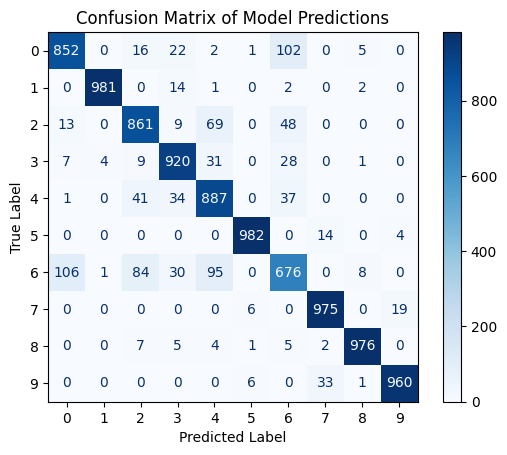

In [36]:

# Step 1: Generate predictions
y_pred = saved_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)  # Convert one-hot to class indices if necessary

# Step 2: Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Step 3: Plot the confusion matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix of Model Predictions')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

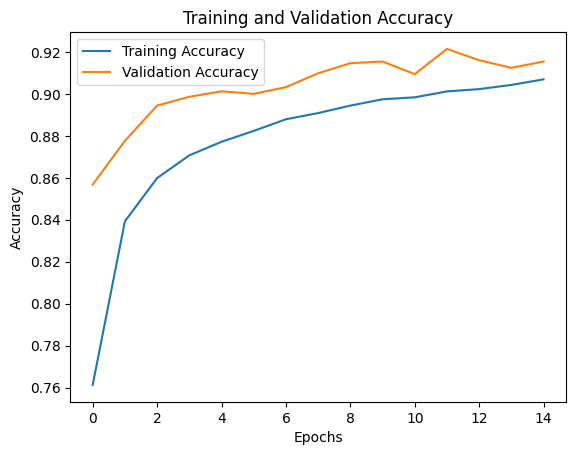

In [37]:
# training & validation accuracy values
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [43]:
import os
import signal
import subprocess

def kill_process_on_port(port):
    try:
        #list of all processes using specified port
        result = subprocess.check_output(["lsof", "-t", f"-i:{port}"])
        pids = result.decode().strip().split("\n")

        for pid in pids:
            os.kill(int(pid), signal.SIGKILL)  # Forcefully kill the process
        print(f"Killed processes on port {port}: {', '.join(pids)}")
    except subprocess.CalledProcessError:
        print(f"No process found on port {port}.")

# port number to free up
PORT = 5003
kill_process_on_port(PORT)



No process found on port 5003.


In [44]:
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf
import threading

# Function to kill processes on a specific port
def kill_process_on_port(port):
    try:
        # Get the list of all processes using the specified port
        result = subprocess.check_output(["lsof", "-t", f"-i:{port}"])
        pids = result.decode().strip().split("\n")

        for pid in pids:
            os.kill(int(pid), signal.SIGKILL)  # Forcefully kill the process
        print(f"Killed processes on port {port}: {', '.join(pids)}")
    except subprocess.CalledProcessError:
        print(f"No process found on port {port}.")

# Initializing Flask 
app = Flask(__name__)

# Loading pre-trained model
model = load_model("model_checkpoint.keras")

#port number to use
PORT = 5003
kill_process_on_port(PORT)

# route for the prediction
@app.route('/predict', methods=['POST'])
def predict():
    # Parse the incoming JSON request for image data
    data = request.get_json()
    if 'image' not in data:
        return jsonify({"error": "No image data found"}), 400

    # Get the image data from the request (expecting it as a 2D list)
    try:
        image_data = X_test[0].reshape(1, 28, 28, 1)  # Reshape as needed
    except ValueError:
        return jsonify({"error": "Invalid image data format"}), 400

    # Make a prediction using the model
    with tf.device("/cpu:0"):  # Explicitly run on CPU if no GPU is available or for compatibility
        prediction = model.predict(image_data)
    
    # Class with the highest probability
    predicted_class = np.argmax(prediction[0])
    confidence = float(np.max(prediction[0]))

    # Return the result as JSON
    return jsonify({
        "predicted_class": int(predicted_class),
        "confidence": confidence
    })

# Function to run the Flask app
def run_app():
    app.run(host="0.0.0.0", port=PORT, debug=True, use_reloader=False)  # Set use_reloader to False

# Run the Flask app in a separate thread
threading.Thread(target=run_app).start()


No process found on port 5003.
 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5003
 * Running on http://192.168.1.121:5003
Press CTRL+C to quit


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


127.0.0.1 - - [31/Oct/2024 20:18:09] "POST /predict HTTP/1.1" 200 -


In [45]:
import requests
import numpy as np

'''# Sample image data to send (reshape it according to your model's input requirements)
# Here we create a dummy image as a 28x28 array filled with zeros (or you can use actual image data)
dummy_image = np.zeros((28, 28)).tolist()  # Convert to list for JSON serialization
'''
#URL for Flask app
url = 'http://127.0.0.1:5003/predict'

#JSON payload
data = {
    "image": [
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.01176471], [0.00392157], [0.], [0.], [0.02745098], [0.], [0.14509804], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.00784314], [0.], [0.10588235], [0.32941176], [0.04313725], [0.], [0.], [0.], [0.], [0.], [0.], [0.46666667], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.], [0.], [0.34509804], [0.56078431], [0.43137255], [0.], [0.], [0.], [0.], [0.08627451], [0.36470588], [0.41568627], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.01568627], [0.], [0.20784314], [0.50588235], [0.47058824], [0.57647059], [0.68627451], [0.61568627], [0.65098039], [0.52941176], [0.60392157], [0.65882353], [0.54901961], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00784314], [0.], [0.04313725], [0.5372549], [0.50980392], [0.50196078], [0.62745098], [0.69019608], [0.62352941], [0.65490196], [0.69803922], [0.58431373], [0.59215686], [0.56470588], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.], [0.00784314], [0.00392157], [0.], [0.01176471], [0.], [0.], [0.45098039], [0.44705882], [0.41568627], [0.5372549], [0.65882353], [0.6], [0.61176471], [0.64705882], [0.65490196], [0.56078431], [0.61568627], [0.61960784], [0.04313725], [0.]],
    [[0.], [0.], [0.], [0.], [0.00392157], [0.], [0.], [0.], [0.], [0.], [0.01176471], [0.], [0.], [0.34901961], [0.54509804], [0.35294118], [0.36862745], [0.6], [0.58431373], [0.51372549], [0.59215686], [0.6627451], [0.6745098], [0.56078431], [0.62352941], [0.6627451], [0.18823529], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.00784314], [0.01568627], [0.00392157], [0.], [0.], [0.], [0.38431373], [0.53333333], [0.43137255], [0.42745098], [0.43137255], [0.63529412], [0.52941176], [0.56470588], [0.58431373], [0.62352941], [0.65490196], [0.56470588], [0.61960784], [0.6627451], [0.46666667], [0.]],
    [[0.], [0.], [0.00784314], [0.00784314], [0.00392157], [0.00784314], [0.], [0.], [0.], [0.], [0.], [0.], [0.09411765], [0.31372549], [0.41960784], [0.31372549], [0.35686275], [0.37647059], [0.62352941], [0.58039216], [0.56470588], [0.67058824], [0.61960784], [0.61176471], [0.65098039], [0.61960784], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.03921569], [0.15686275], [0.4], [0.23921569], [0.38039216], [0.30980392], [0.35294118], [0.5372549], [0.62745098], [0.6], [0.61568627], [0.6], [0.52156863], [0.18039216], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.35294118], [0.50196078], [0.58823529], [0.61176471], [0.59215686], [0.54117647], [0.54117647], [0.32156863], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]]
  ]

    
}

# Send a POST request
response = requests.post(url, json=data)

# Print the response
print("Status Code:", response.status_code)
print("Response JSON:", response.json())



Status Code: 200
Response JSON: {'confidence': 0.9997206330299377, 'predicted_class': 9}


In [46]:
class_names[response.json()['predicted_class']]

'Ankle boot'